In [1]:
# ==========================================================
# CELL 1: IMPORT LIBRARIES AND CREATE PROJECT FOLDERS
# ==========================================================

import os
import time
import json
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path
from joblib import dump

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("All libraries imported successfully.")
print("TensorFlow version:", tf.__version__)


# ==========================================================
# PROJECT FOLDER LOCATION
# ==========================================================

PROJECT_DIR = Path(
    r"C:\Users\drish\assignment_ANN_classification"
)

DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"
FIGURES_DIR = PROJECT_DIR / "Figures"

ITERATION_DIR = FIGURES_DIR / "iteration_loss"
EPOCH_DIR = FIGURES_DIR / "epoch_loss"
CM_DIR = FIGURES_DIR / "confusion_matrix"
COMPARISON_DIR = FIGURES_DIR / "comparison"

# Create all folders
for folder in [
    DATA_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    ITERATION_DIR,
    EPOCH_DIR,
    CM_DIR,
    COMPARISON_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("\nProject folders created successfully.")
print("Project location:", PROJECT_DIR)

All libraries imported successfully.
TensorFlow version: 2.22.0-rc0

Project folders created successfully.
Project location: C:\Users\drish\assignment_ANN_classification


In [2]:
data_path = DATA_DIR / "HTRU_2.csv"

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {data_path}\n"
        "Place HTRU_2.csv inside the Data folder."
    )

column_names = [
    "Mean_IP",
    "SD_IP",
    "Excess_Kurtosis_IP",
    "Skewness_IP",
    "Mean_DM_SNR",
    "SD_DM_SNR",
    "Excess_Kurtosis_DM_SNR",
    "Skewness_DM_SNR",
    "Class"
]

df = pd.read_csv(
    data_path,
    header=None,
    names=column_names
)

print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nClass distribution:")
print(df["Class"].value_counts().sort_index())

DATASET LOADED SUCCESSFULLY
Dataset shape: (17898, 9)


,Mean_IP,SD_IP,Excess_Kurtosis_IP,Skewness_IP,Mean_DM_SNR,SD_DM_SNR,Excess_Kurtosis_DM_SNR,Skewness_DM_SNR,Class
0,140.562500,55.683782,-0.234571,-0.699648,3.199833,19.110426,7.975532,74.242225,0
1,102.507812,58.882430,0.465318,-0.515088,1.677258,14.860146,10.576487,127.393580,0
2,103.015625,39.341649,0.323328,1.051164,3.121237,21.744669,7.735822,63.171909,0
3,136.750000,57.178449,-0.068415,-0.636238,3.642977,20.959280,6.896499,53.593661,0
4,88.726562,40.672225,0.600866,1.123492,1.178930,11.468720,14.269573,252.567306,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 17898 entries, 0 to 17897
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Mean_IP                 17898 non-null  float64
 1   SD_IP                   17898 non-null  float64
 2   Excess_Kurtosis_IP      17898 non-null  float64
 3   Skewness_IP             17898 non-null  float64
 4   Mean_DM_SNR             17898 non-null  float64
 5   SD_DM_SNR               17898 non-null  float64
 6   Excess_Kurtosis_DM_SNR  17898 non-null  float64
 7   Skewness_DM_SNR         17898 non-null  float64
 8   Class                   17898 non-null  int64  
dtypes: float64(8), int64(1)
memory usage: 1.2 MB

Missing values:
Mean_IP                   0
SD_IP                     0
Excess_Kurtosis_IP        0
Skewness_IP               0
Mean_DM_SNR               0
SD_DM_SNR                 0
Excess_Kurtosis_DM_SNR    0
Skewness_DM_SNR           0
Class  

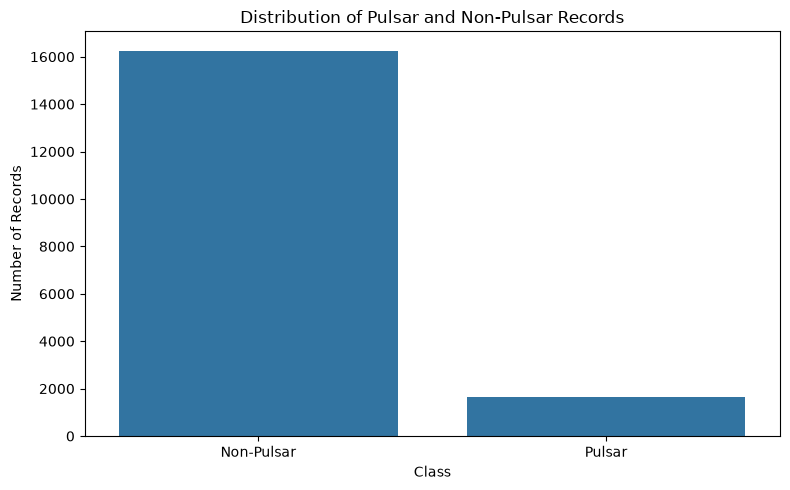

In [3]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribution of Pulsar and Non-Pulsar Records")
plt.xlabel("Class")
plt.ylabel("Number of Records")

plt.xticks(
    [0, 1],
    ["Non-Pulsar", "Pulsar"]
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "class_distribution.png",
    dpi=300
)

plt.show()
plt.close()

In [4]:
X = df.drop(columns=["Class"])
y = df["Class"].astype(int)

print("INPUT FEATURES:", X.shape)
print("TARGET VARIABLE:", y.shape)

print("\nNumber of input features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

INPUT FEATURES: (17898, 8)
TARGET VARIABLE: (17898,)

Number of input features: 8
Target classes: [np.int64(0), np.int64(1)]


In [5]:
X_train_pool, X_test_raw, y_train_pool, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_pool
)

print("TRAINING DATA:", X_train_raw.shape)
print("VALIDATION DATA:", X_val_raw.shape)
print("TESTING DATA:", X_test_raw.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

TRAINING DATA: (11454, 8)
VALIDATION DATA: (2864, 8)
TESTING DATA: (3580, 8)

Training class distribution:
Class
0    10405
1     1049
Name: count, dtype: int64

Validation class distribution:
Class
0    2602
1     262
Name: count, dtype: int64

Testing class distribution:
Class
0    3252
1     328
Name: count, dtype: int64


In [6]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

dump(
    scaler,
    MODEL_DIR / "standard_scaler.pkl"
)

print("Standardization completed.")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining mean:", np.mean(X_train))
print("Training standard deviation:", np.std(X_train))

Standardization completed.
Training: (11454, 8)
Validation: (2864, 8)
Testing: (3580, 8)

Training mean: 1.9975096989239764e-16
Training standard deviation: 1.0


In [7]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

CLASS_WEIGHTS = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("CLASS WEIGHTS")

for cls, weight in CLASS_WEIGHTS.items():
    print(f"Class {cls}: {weight:.4f}")

CLASS WEIGHTS
Class 0: 0.5504
Class 1: 5.4595


In [8]:
ARCHITECTURES = {

    5: [128, 64, 32, 16, 8],

    7: [128, 128, 64, 64, 32, 16, 8],

    10: [128, 128, 64, 64, 32, 32, 16, 16, 8, 8]

}

ACTIVATIONS = [
    "relu",
    "tanh",
    "leaky_relu"
]

LEARNING_RATES = [
    0.01,
    0.001,
    0.0001
]

EPOCHS = 100
BATCH_SIZE = 32

EXPERIMENTS = [
    (depth, activation, lr)
    for depth in ARCHITECTURES
    for activation in ACTIVATIONS
    for lr in LEARNING_RATES
]

print("Total ANN experiments:", len(EXPERIMENTS))

print("\nHidden layers:", list(ARCHITECTURES.keys()))
print("Activations:", ACTIVATIONS)
print("Learning rates:", LEARNING_RATES)

Total ANN experiments: 27

Hidden layers: [5, 7, 10]
Activations: ['relu', 'tanh', 'leaky_relu']
Learning rates: [0.01, 0.001, 0.0001]


In [9]:
def build_ann(depth, activation, learning_rate):

    model = tf.keras.Sequential()

    model.add(
        tf.keras.layers.Input(
            shape=(X_train.shape[1],)
        )
    )

    for units in ARCHITECTURES[depth]:

        model.add(
            tf.keras.layers.Dense(units)
        )

        if activation == "leaky_relu":

            try:
                layer = tf.keras.layers.LeakyReLU(
                    negative_slope=0.01
                )

            except TypeError:
                layer = tf.keras.layers.LeakyReLU(
                    alpha=0.01
                )

            model.add(layer)

        else:

            model.add(
                tf.keras.layers.Activation(activation)
            )

    model.add(
        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    )

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

In [10]:
class IterationLossCallback(
    tf.keras.callbacks.Callback
):

    def __init__(self):

        super().__init__()

        self.iterations = []
        self.losses = []
        self.step = 0

    def on_train_batch_end(self, batch, logs=None):

        self.step += 1

        self.iterations.append(self.step)

        self.losses.append(
            logs.get("loss")
        )

In [11]:
def calculate_metrics(y_true, y_pred):

    return {

        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),

        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )

    }

In [12]:
ann_results = []

best_validation_f1 = -1
best_config = None

for experiment_no, (depth, activation, lr) in enumerate(
    EXPERIMENTS, 1
):

    print("\n" + "=" * 70)

    print(f"EXPERIMENT {experiment_no}/27")
    print("Hidden layers:", depth)
    print("Activation:", activation)
    print("Learning rate:", lr)

    print("=" * 70)

    tf.keras.backend.clear_session()

    model = build_ann(
        depth,
        activation,
        lr
    )

    iteration_callback = IterationLossCallback()

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    start_time = time.perf_counter()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=CLASS_WEIGHTS,
        callbacks=[
            iteration_callback,
            early_stop
        ],
        verbose=0
    )

    training_time = time.perf_counter() - start_time

    # Validation predictions

    val_probabilities = model.predict(
        X_val,
        verbose=0
    ).ravel()

    val_predictions = (
        val_probabilities >= 0.5
    ).astype(int)

    metrics = calculate_metrics(
        y_val,
        val_predictions
    )

    experiment_name = (
        f"L{depth}_{activation}_LR{lr}"
    )

    epochs_completed = len(
        history.history["loss"]
    )

    # Store experiment results

    ann_results.append({

        "Experiment": experiment_name,

        "Layers": depth,

        "Activation": activation,

        "Learning Rate": lr,

        "Epochs Completed": epochs_completed,

        "Validation Loss": min(
            history.history["val_loss"]
        ),

        "Validation Accuracy": metrics["Accuracy"],

        "Validation Precision": metrics["Precision"],

        "Validation Recall": metrics["Recall"],

        "Validation F1": metrics["F1-Score"],

        "Training Time (s)": training_time

    })

    # Save iteration history

    iteration_df = pd.DataFrame({

        "Iteration": iteration_callback.iterations,

        "Training Loss": iteration_callback.losses

    })

    iteration_df.to_csv(
        RESULTS_DIR / f"{experiment_name}_iteration_history.csv",
        index=False
    )

    # Iteration loss plot

    plt.figure(figsize=(9, 5))

    plt.plot(
        iteration_callback.iterations,
        iteration_callback.losses
    )

    plt.title(
        f"Training Error vs Iterations - {experiment_name}"
    )

    plt.xlabel("Iteration")
    plt.ylabel("Binary Cross-Entropy Loss")

    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(
        ITERATION_DIR / f"{experiment_name}.png",
        dpi=200
    )

    plt.close()

    # Epoch loss plot

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(
        f"Training and Validation Loss - {experiment_name}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")

    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        EPOCH_DIR / f"{experiment_name}.png",
        dpi=200
    )

    plt.close()

    # Save best model based on validation F1

    if metrics["F1-Score"] > best_validation_f1:

        best_validation_f1 = metrics["F1-Score"]

        best_config = (
            depth,
            activation,
            lr
        )

        model.save(
            MODEL_DIR / "best_ann_classification.keras"
        )

    print(
        f"Validation Accuracy: {metrics['Accuracy']:.4f}"
    )

    print(
        f"Validation Precision: {metrics['Precision']:.4f}"
    )

    print(
        f"Validation Recall: {metrics['Recall']:.4f}"
    )

    print(
        f"Validation F1: {metrics['F1-Score']:.4f}"
    )

    print(
        f"Training time: {training_time:.2f} seconds"
    )


# Save experiment results

ann_results_df = pd.DataFrame(ann_results)

ann_results_df = ann_results_df.sort_values(
    by="Validation F1",
    ascending=False
)

ann_results_df.to_csv(
    RESULTS_DIR / "ann_experiment_results.csv",
    index=False
)

print("\nALL 27 EXPERIMENTS COMPLETED.")

display(ann_results_df)


EXPERIMENT 1/27
Hidden layers: 5
Activation: relu
Learning rate: 0.01

Validation Accuracy: 0.9616
Validation Precision: 0.7289
Validation Recall: 0.9237
Validation F1: 0.8148
Training time: 12.18 seconds

EXPERIMENT 2/27
Hidden layers: 5
Activation: relu
Learning rate: 0.001
Validation Accuracy: 0.9658
Validation Precision: 0.7562
Validation Recall: 0.9237
Validation F1: 0.8316
Training time: 31.64 seconds

EXPERIMENT 3/27
Hidden layers: 5
Activation: relu
Learning rate: 0.0001
Validation Accuracy: 0.9661
Validation Precision: 0.7603
Validation Recall: 0.9198
Validation F1: 0.8325
Training time: 74.22 seconds

EXPERIMENT 4/27
Hidden layers: 5
Activation: tanh
Learning rate: 0.01
Validation Accuracy: 0.9724
Validation Precision: 0.8188
Validation Recall: 0.8969
Validation F1: 0.8561
Training time: 30.49 seconds

EXPERIMENT 5/27
Hidden layers: 5
Activation: tanh
Learning rate: 0.001
Validation Accuracy: 0.9633
Validation Precision: 0.7415
Validation Recall: 0.9198
Validation F1: 0.8211

,Experiment,Layers,Activation,Learning Rate,Epochs Completed,Validation Loss,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Training Time (s)
12,L7_tanh_LR0.01,7,tanh,0.0100,42,0.156717,0.975209,0.886640,0.835878,0.860511,34.285236
26,L10_leaky_relu_LR0.0001,10,leaky_relu,0.0001,78,0.107489,0.972067,0.807432,0.912214,0.856631,84.731036
3,L5_tanh_LR0.01,5,tanh,0.0100,36,0.122943,0.972416,0.818815,0.896947,0.856102,30.494702
13,L7_tanh_LR0.001,7,tanh,0.0010,58,0.118152,0.969623,0.788779,0.912214,0.846018,58.726334
22,L10_tanh_LR0.001,10,tanh,0.0010,37,0.134857,0.967528,0.771704,0.916031,0.837696,37.804942
9,L7_relu_LR0.01,7,relu,0.0100,19,0.169874,0.968575,0.798611,0.877863,0.836364,20.482376
11,L7_relu_LR0.0001,7,relu,0.0001,90,0.124216,0.966830,0.765079,0.919847,0.835355,85.548317
18,L10_relu_LR0.01,10,relu,0.0100,28,0.134814,0.966830,0.766773,0.916031,0.834783,29.864528
25,L10_leaky_relu_LR0.001,10,leaky_relu,0.0010,24,0.110312,0.966480,0.761006,0.923664,0.834483,37.148971
8,L5_leaky_relu_LR0.0001,5,leaky_relu,0.0001,95,0.122844,0.966480,0.761006,0.923664,0.834483,75.033066


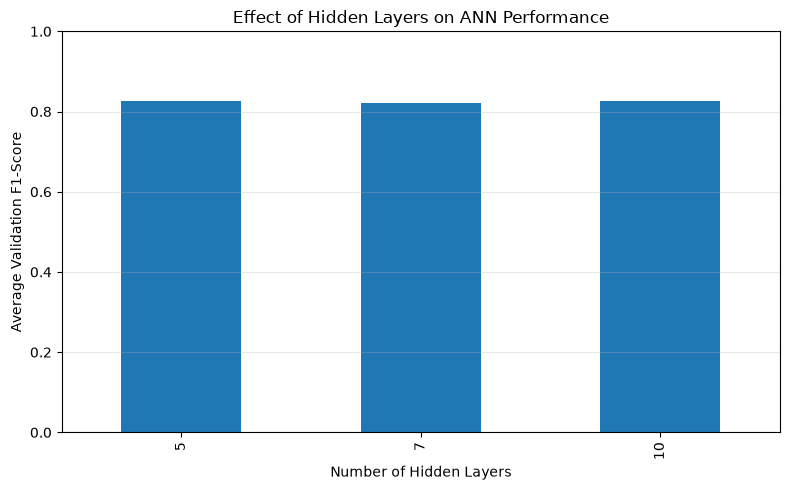

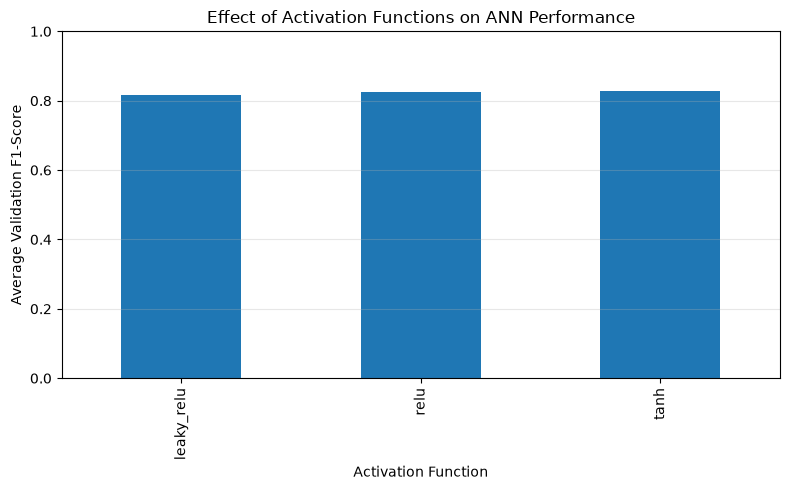

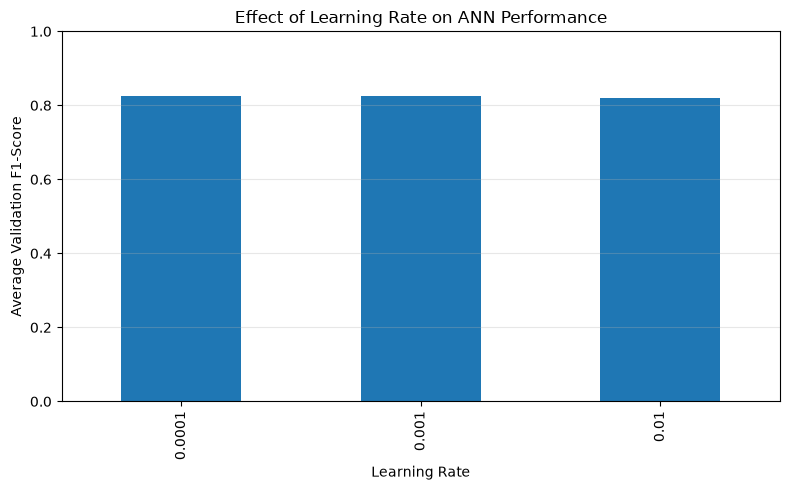

In [13]:
# Effect of hidden layers

layer_effect = ann_results_df.groupby(
    "Layers"
)["Validation F1"].mean()

plt.figure(figsize=(8, 5))

layer_effect.plot(kind="bar")

plt.title("Effect of Hidden Layers on ANN Performance")
plt.xlabel("Number of Hidden Layers")
plt.ylabel("Average Validation F1-Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "layer_effect.png",
    dpi=300
)

plt.show()
plt.close()


# Effect of activation functions

activation_effect = ann_results_df.groupby(
    "Activation"
)["Validation F1"].mean()

plt.figure(figsize=(8, 5))

activation_effect.plot(kind="bar")

plt.title("Effect of Activation Functions on ANN Performance")
plt.xlabel("Activation Function")
plt.ylabel("Average Validation F1-Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "activation_effect.png",
    dpi=300
)

plt.show()
plt.close()


# Effect of learning rates

lr_effect = ann_results_df.groupby(
    "Learning Rate"
)["Validation F1"].mean()

plt.figure(figsize=(8, 5))

lr_effect.plot(kind="bar")

plt.title("Effect of Learning Rate on ANN Performance")
plt.xlabel("Learning Rate")
plt.ylabel("Average Validation F1-Score")

plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "learning_rate_effect.png",
    dpi=300
)

plt.show()
plt.close()

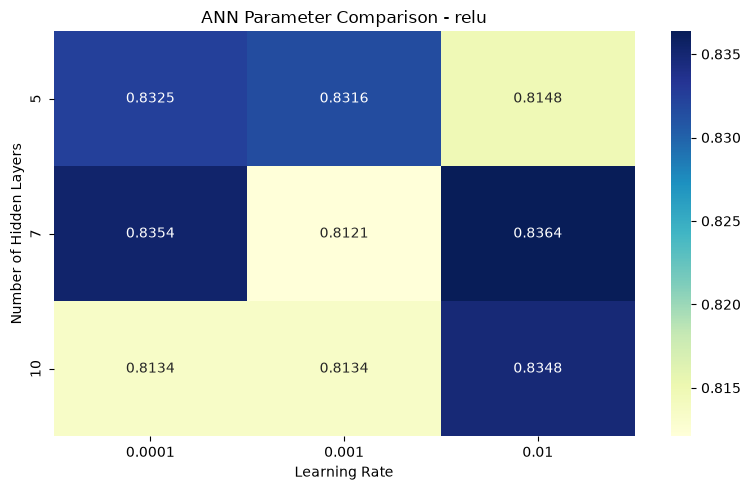

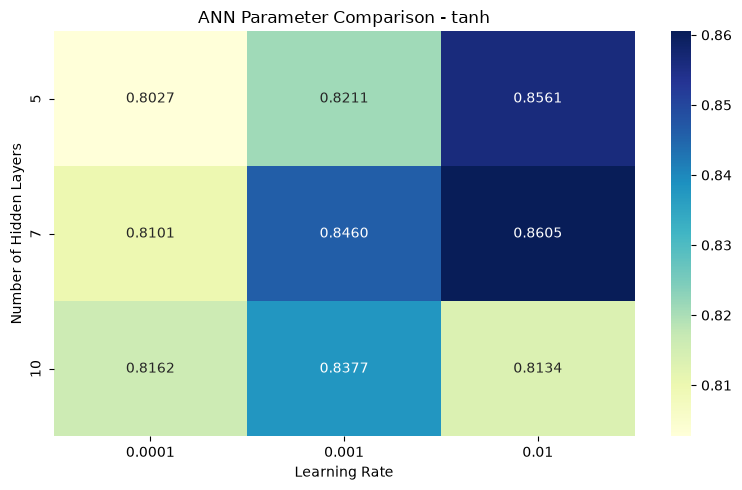

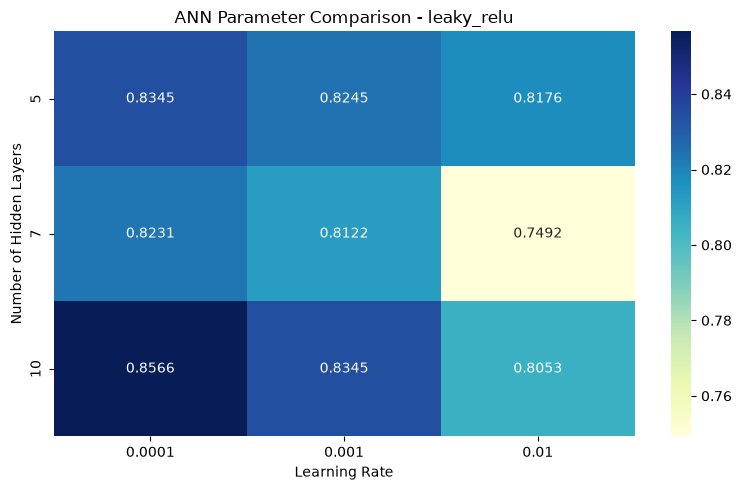

In [14]:
for activation in ACTIVATIONS:

    subset = ann_results_df[
        ann_results_df["Activation"] == activation
    ]

    pivot = subset.pivot(
        index="Layers",
        columns="Learning Rate",
        values="Validation F1"
    )

    plt.figure(figsize=(8, 5))

    sns.heatmap(
        pivot,
        annot=True,
        fmt=".4f",
        cmap="YlGnBu"
    )

    plt.title(
        f"ANN Parameter Comparison - {activation}"
    )

    plt.xlabel("Learning Rate")
    plt.ylabel("Number of Hidden Layers")

    plt.tight_layout()

    plt.savefig(
        COMPARISON_DIR / f"heatmap_{activation}.png",
        dpi=300
    )

    plt.show()
    plt.close()

In [15]:
best_model = tf.keras.models.load_model(
    MODEL_DIR / "best_ann_classification.keras"
)

y_test_prob = best_model.predict(
    X_test,
    verbose=0
).ravel()

y_test_pred = (
    y_test_prob >= 0.5
).astype(int)

ann_test_metrics = calculate_metrics(
    y_test,
    y_test_pred
)

print("=" * 60)
print("FINAL ANN TEST RESULTS")
print("=" * 60)

for metric, value in ann_test_metrics.items():

    print(f"{metric}: {value:.4f}")


print("\nCLASSIFICATION REPORT")

ann_report = classification_report(
    y_test,
    y_test_pred,
    target_names=[
        "Non-Pulsar",
        "Pulsar"
    ],
    zero_division=0
)

print(ann_report)

with open(
    RESULTS_DIR / "ann_classification_report.txt",
    "w"
) as f:

    f.write(ann_report)

FINAL ANN TEST RESULTS
Accuracy: 0.9785
Precision: 0.8838
Recall: 0.8811
F1-Score: 0.8824

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  Non-Pulsar       0.99      0.99      0.99      3252
      Pulsar       0.88      0.88      0.88       328

    accuracy                           0.98      3580
   macro avg       0.94      0.93      0.94      3580
weighted avg       0.98      0.98      0.98      3580



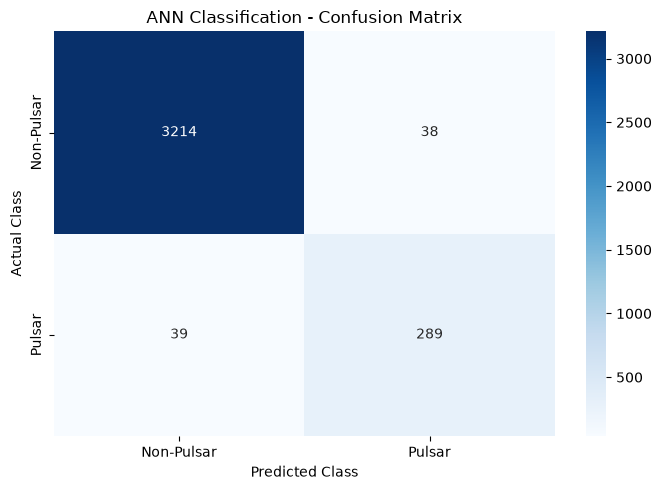

In [16]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Non-Pulsar",
        "Pulsar"
    ],
    yticklabels=[
        "Non-Pulsar",
        "Pulsar"
    ]
)

plt.title("ANN Classification - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    CM_DIR / "ann_confusion_matrix.png",
    dpi=300
)

plt.show()
plt.close()

In [17]:
baseline_results = []

best_svm = None
best_svm_f1 = -1
best_svm_name = None

best_dt = None
best_dt_f1 = -1
best_dt_name = None


# SVM experiments

for kernel in ["linear", "poly", "rbf"]:

    model = SVC(
        kernel=kernel,
        class_weight="balanced",
        random_state=SEED
    )

    model.fit(
        X_train,
        y_train
    )

    val_pred = model.predict(X_val)

    metrics = calculate_metrics(
        y_val,
        val_pred
    )

    name = f"SVM - {kernel}"

    baseline_results.append({

        "Model": name,
        "Family": "SVM",
        **metrics

    })

    if metrics["F1-Score"] > best_svm_f1:

        best_svm_f1 = metrics["F1-Score"]
        best_svm = model
        best_svm_name = name


# Decision Tree experiments

for depth in [3, 5, 10, None]:

    for min_split in [2, 5, 10]:

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_split=min_split,
            class_weight="balanced",
            random_state=SEED
        )

        model.fit(
            X_train,
            y_train
        )

        val_pred = model.predict(X_val)

        metrics = calculate_metrics(
            y_val,
            val_pred
        )

        name = (
            f"Decision Tree - depth={depth}, "
            f"min_split={min_split}"
        )

        baseline_results.append({

            "Model": name,
            "Family": "Decision Tree",
            **metrics

        })

        if metrics["F1-Score"] > best_dt_f1:

            best_dt_f1 = metrics["F1-Score"]
            best_dt = model
            best_dt_name = name


baseline_df = pd.DataFrame(
    baseline_results
)

baseline_df.to_csv(
    RESULTS_DIR / "svm_dt_validation_results.csv",
    index=False
)

print("BEST SVM:", best_svm_name)
print("SVM Validation F1:", round(best_svm_f1, 4))

print("\nBEST DECISION TREE:", best_dt_name)
print("Decision Tree Validation F1:", round(best_dt_f1, 4))

BEST SVM: SVM - rbf
SVM Validation F1: 0.8645

BEST DECISION TREE: Decision Tree - depth=5, min_split=2
Decision Tree Validation F1: 0.8294


In [18]:
final_models = {

    "ANN": best_model,

    "SVM": best_svm,

    "Decision Tree": best_dt

}

final_results = []

for name, model in final_models.items():

    if name == "ANN":

        predictions = y_test_pred

    else:

        predictions = model.predict(X_test)

    metrics = calculate_metrics(
        y_test,
        predictions
    )

    final_results.append({

        "Model": name,
        **metrics

    })


final_comparison_df = pd.DataFrame(
    final_results
)

final_comparison_df = final_comparison_df.sort_values(
    by="F1-Score",
    ascending=False
)

print("FINAL MODEL COMPARISON")

display(final_comparison_df)

final_comparison_df.to_csv(
    RESULTS_DIR / "final_comparison.csv",
    index=False
)

FINAL MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.978492,0.883792,0.881098,0.882443
1,SVM,0.972905,0.813008,0.914634,0.860832
2,Decision Tree,0.967598,0.776042,0.908537,0.837079


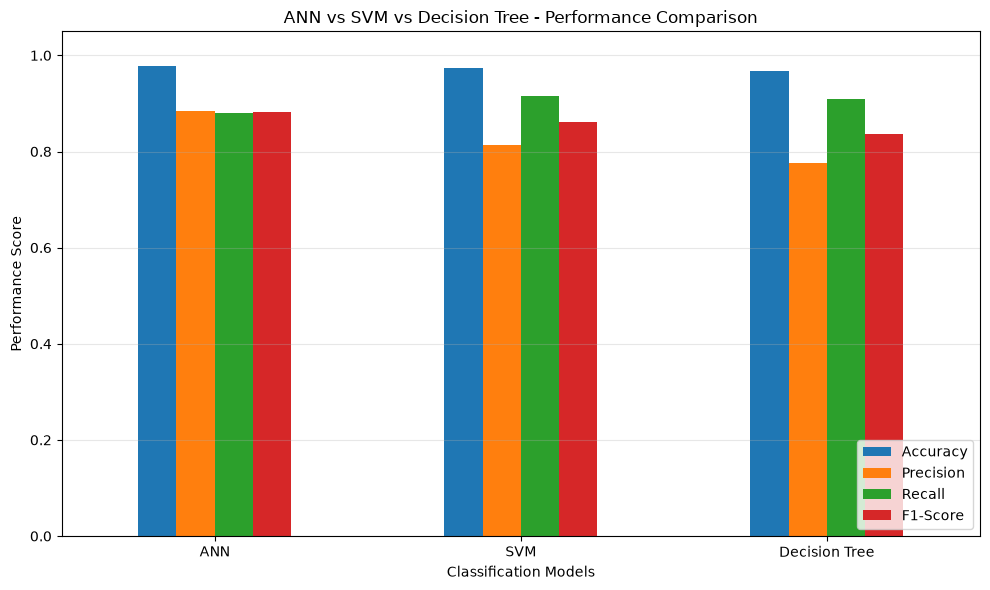

In [19]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

plot_df = final_comparison_df.set_index(
    "Model"
)[metrics]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "ANN vs SVM vs Decision Tree - Performance Comparison"
)

plt.ylabel("Performance Score")
plt.xlabel("Classification Models")

plt.ylim(0, 1.05)

plt.xticks(rotation=0)

plt.legend(loc="lower right")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    COMPARISON_DIR / "ann_svm_dt_comparison.png",
    dpi=300
)

plt.show()
plt.close()

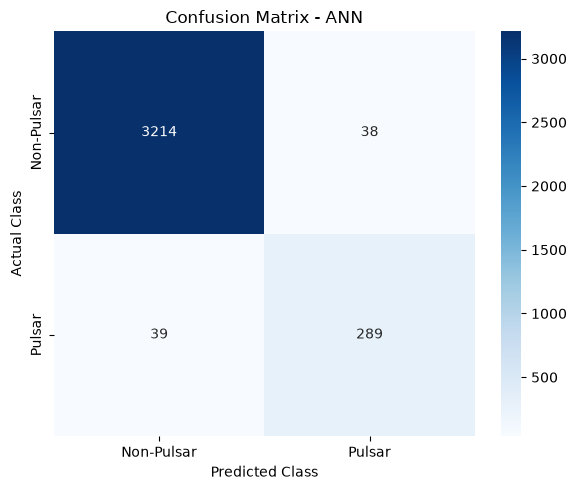

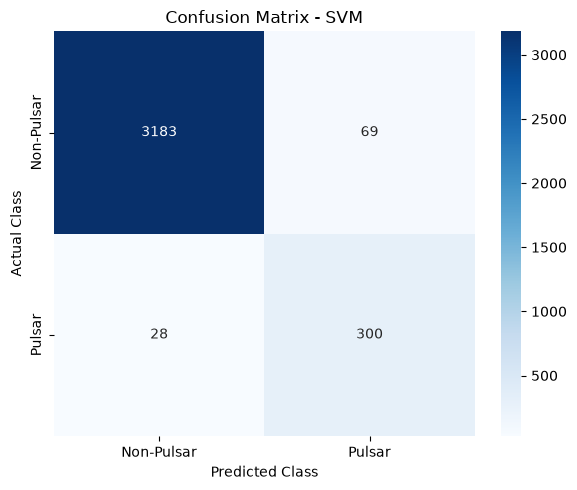

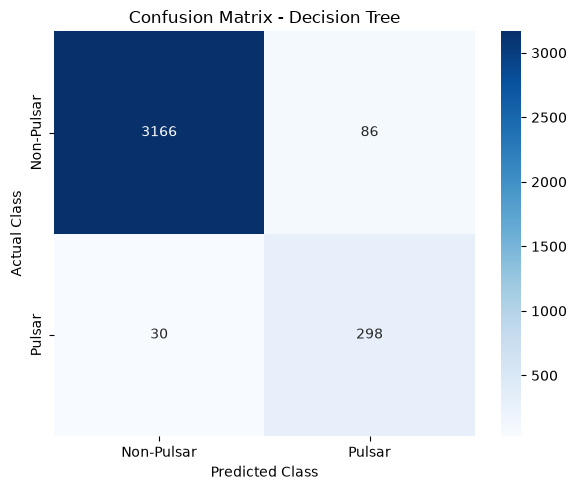

In [20]:
for name, model in final_models.items():

    if name == "ANN":

        predictions = y_test_pred

    else:

        predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Non-Pulsar",
            "Pulsar"
        ],
        yticklabels=[
            "Non-Pulsar",
            "Pulsar"
        ]
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()

    safe_name = name.lower().replace(" ", "_")

    plt.savefig(
        CM_DIR / f"{safe_name}_confusion_matrix.png",
        dpi=300
    )

    plt.show()
    plt.close()

In [21]:
dump(
    best_svm,
    MODEL_DIR / "best_svm_model.pkl"
)

dump(
    best_dt,
    MODEL_DIR / "best_decision_tree_model.pkl"
)

print("SVM model saved.")
print("Decision Tree model saved.")

SVM model saved.
Decision Tree model saved.


In [22]:
summary = {

    "Dataset": "HTRU_2.csv",

    "Target Variable": "Class",

    "Number of Samples": int(len(df)),

    "Number of Features": int(X.shape[1]),

    "Training Samples": int(len(X_train)),

    "Validation Samples": int(len(X_val)),

    "Testing Samples": int(len(X_test)),

    "Best ANN Hidden Layers": int(best_config[0]),

    "Best ANN Activation": best_config[1],

    "Best ANN Learning Rate": float(best_config[2]),

    "ANN Test Accuracy": float(
        ann_test_metrics["Accuracy"]
    ),

    "ANN Test Precision": float(
        ann_test_metrics["Precision"]
    ),

    "ANN Test Recall": float(
        ann_test_metrics["Recall"]
    ),

    "ANN Test F1": float(
        ann_test_metrics["F1-Score"]
    )

}

with open(
    RESULTS_DIR / "final_summary.json",
    "w"
) as f:

    json.dump(
        summary,
        f,
        indent=4
    )

print("Final summary saved successfully.")

Final summary saved successfully.


In [23]:
requirements = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "tensorflow",
    "joblib"
]

with open(
    PROJECT_DIR / "requirements.txt",
    "w"
) as f:

    f.write("\n".join(requirements))


readme = """
# ANN Classification - HTRU-2 Pulsar Dataset

## Objective
To classify pulsar and non-pulsar candidates using
an Artificial Neural Network.

## Dataset
HTRU-2 Pulsar Dataset.

## Target Variable
Class:
- 0: Non-Pulsar
- 1: Pulsar

## Input Features
Eight numerical features from the HTRU-2 dataset.

## ANN Experiments
- Hidden layers: 5, 7 and 10
- Activation functions: ReLU, tanh and LeakyReLU
- Learning rates: 0.01, 0.001 and 0.0001
- Optimizer: Adam
- Loss function: Binary Cross-Entropy

Total ANN configurations: 27.

## Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

## Model Comparison
The selected ANN model is compared with SVM and
Decision Tree using the same test dataset.

## Folder Structure
- Data: Input dataset
- Models: Saved trained models
- Results: Experiment results and evaluation reports
- Figures: Training plots and comparison graphs
"""

with open(
    PROJECT_DIR / "README.md",
    "w"
) as f:

    f.write(readme)


print("README.md created.")
print("requirements.txt created.")

README.md created.
requirements.txt created.


In [24]:
print("=" * 65)
print("ANN CLASSIFICATION PROJECT COMPLETED")
print("=" * 65)

print("\nBest ANN configuration:")
print("Layers:", best_config[0])
print("Activation:", best_config[1])
print("Learning rate:", best_config[2])

print("\nFinal model comparison:")
display(final_comparison_df)

print("\nNumber of ANN experiments:", len(ann_results_df))

print("\nProject folder:")
print(PROJECT_DIR)

print("\nModels folder:")
print(MODEL_DIR)

print("\nResults folder:")
print(RESULTS_DIR)

print("\nFigures folder:")
print(FIGURES_DIR)

ANN CLASSIFICATION PROJECT COMPLETED

Best ANN configuration:
Layers: 7
Activation: tanh
Learning rate: 0.01

Final model comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,ANN,0.978492,0.883792,0.881098,0.882443
1,SVM,0.972905,0.813008,0.914634,0.860832
2,Decision Tree,0.967598,0.776042,0.908537,0.837079



Number of ANN experiments: 27

Project folder:
C:\Users\drish\assignment_ANN_classification

Models folder:
C:\Users\drish\assignment_ANN_classification\Models

Results folder:
C:\Users\drish\assignment_ANN_classification\Results

Figures folder:
C:\Users\drish\assignment_ANN_classification\Figures
